# Notebook 01: Data Understanding & Exploratory Data Analysis
### ComplaintScope: A Text, Topic and Network Analytics System
**Course:** CBS3009 – Advanced Social, Text and Media Analytics | **Rubric:** Data Collection & Preprocessing (3 Marks)

---
### 1. Objectives of this Notebook
1. Ingest and document the CFPB Consumer Complaint Database and historical narrative corpus.
2. Characterize the ingestion and filtering funnel (date range, minimum length, deduplication).
3. Analyze class distributions, severe outcome imbalance (relief vs. non-relief), and narrative length distributions.
4. Establish strict chronological split boundaries (70% train, 15% val, 15% test) to prevent lookahead bias.
5. Formulate data quality findings directly informing subsequent preprocessing and modeling.


In [1]:
import sys
from pathlib import Path
# Add project root to sys.path
sys.path.insert(0, str(Path("..").resolve()))

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import load_config, get_path
from src.viz import set_plot_style

set_plot_style()
cfg = load_config()
print(f"Project: {cfg['project_name']} | Mode: {cfg['mode']} | Seed: {cfg['seed']}")


Project: ComplaintScope | Mode: fast | Seed: 42


In [2]:
clean_path = get_path('interim_clean')
df = pd.read_parquet(clean_path)
print(f"Cleaned Modelling Corpus Shape: {df.shape}")
print("\nVariables and Data Types:")
print(df.dtypes)
df.head(3)


Cleaned Modelling Corpus Shape: (19998, 21)

Variables and Data Types:
date_received              datetime64[us]
product                            object
sub_product                        object
issue                              object
sub_issue                          object
narrative                          object
company_public_response            object
company                            object
state                              object
tags                               object
submitted_via                      object
date_sent_to_company       datetime64[us]
company_response                   object
timely_response                    object
complaint_id                       object
narrative_word_count                int64
product_consolidated               object
relief                              int64
month                              object
chronological_split                object
random_split                       object
dtype: object


,date_received,product,sub_product,issue,sub_issue,narrative,company_public_response,company,state,tags,...,date_sent_to_company,company_response,timely_response,complaint_id,narrative_word_count,product_consolidated,relief,month,chronological_split,random_split
0,2018-07-19,"Money transfer, virtual currency, or money ser...",Mobile or digital wallet,Fraud or scam,None,"I applied for loans online, a company named Ca...",None,"COMMUNITY CHOICE FINANCIAL, INC.",FL,None,...,2018-07-19,Closed with explanation,Yes,2968199,431,Money transfer/virtual currency,0,2018-07,train,train
1,2018-07-20,"Credit reporting, credit repair services, or o...",Credit reporting,Unable to get your credit report or credit score,Other problem getting your report or credit score,"On XX/XX/2018, I sought to establish a utility...",None,"EQUIFAX, INC.",OH,None,...,2018-07-20,Closed with explanation,Yes,2969041,206,Credit reporting & repair,0,2018-07,train,train
2,2018-07-20,Debt collection,I do not know,Communication tactics,"Used obscene, profane, or other abusive language",I had a phone call from this company XXXX XXXX...,None,"STONELEIGH RECOVERY ASSOCIATES, LLC",TN,None,...,2018-07-20,Closed with explanation,Yes,2968729,227,Debt collection,0,2018-07,train,val


### 2. Ingestion & Quality Funnel
The pipeline applies systematic quality filters:
- Removal of records outside target date window (2018–2023)
- Enforcement of $\ge 20$ words narrative threshold to filter short non-informative phrases
- Exact narrative deduplication to discard recurring boilerplate copy-pastes
- Extraction of unambiguous company dispute relief outcomes


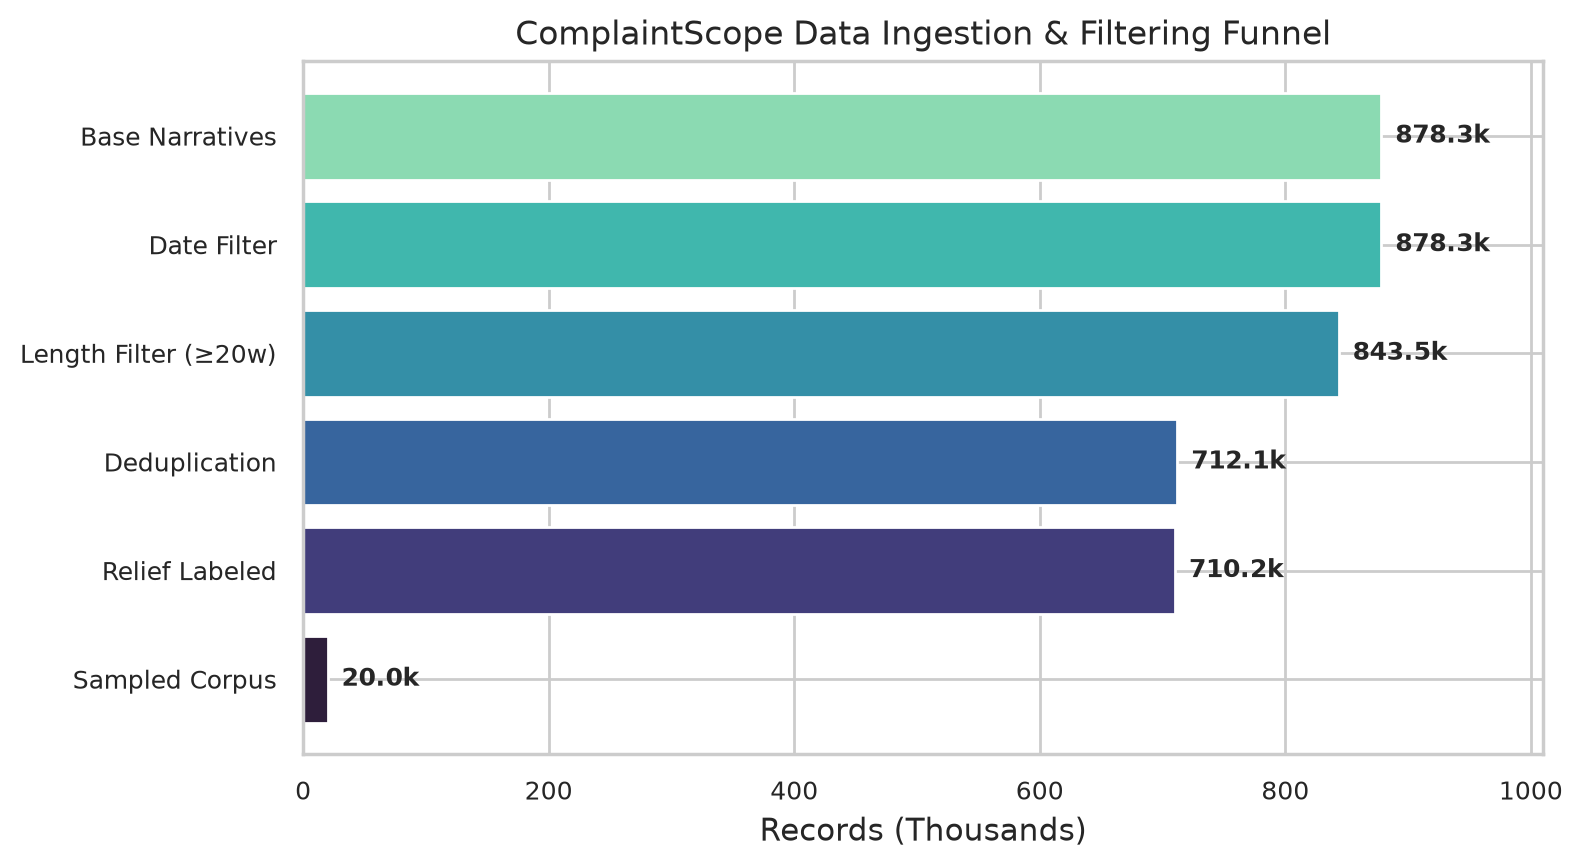

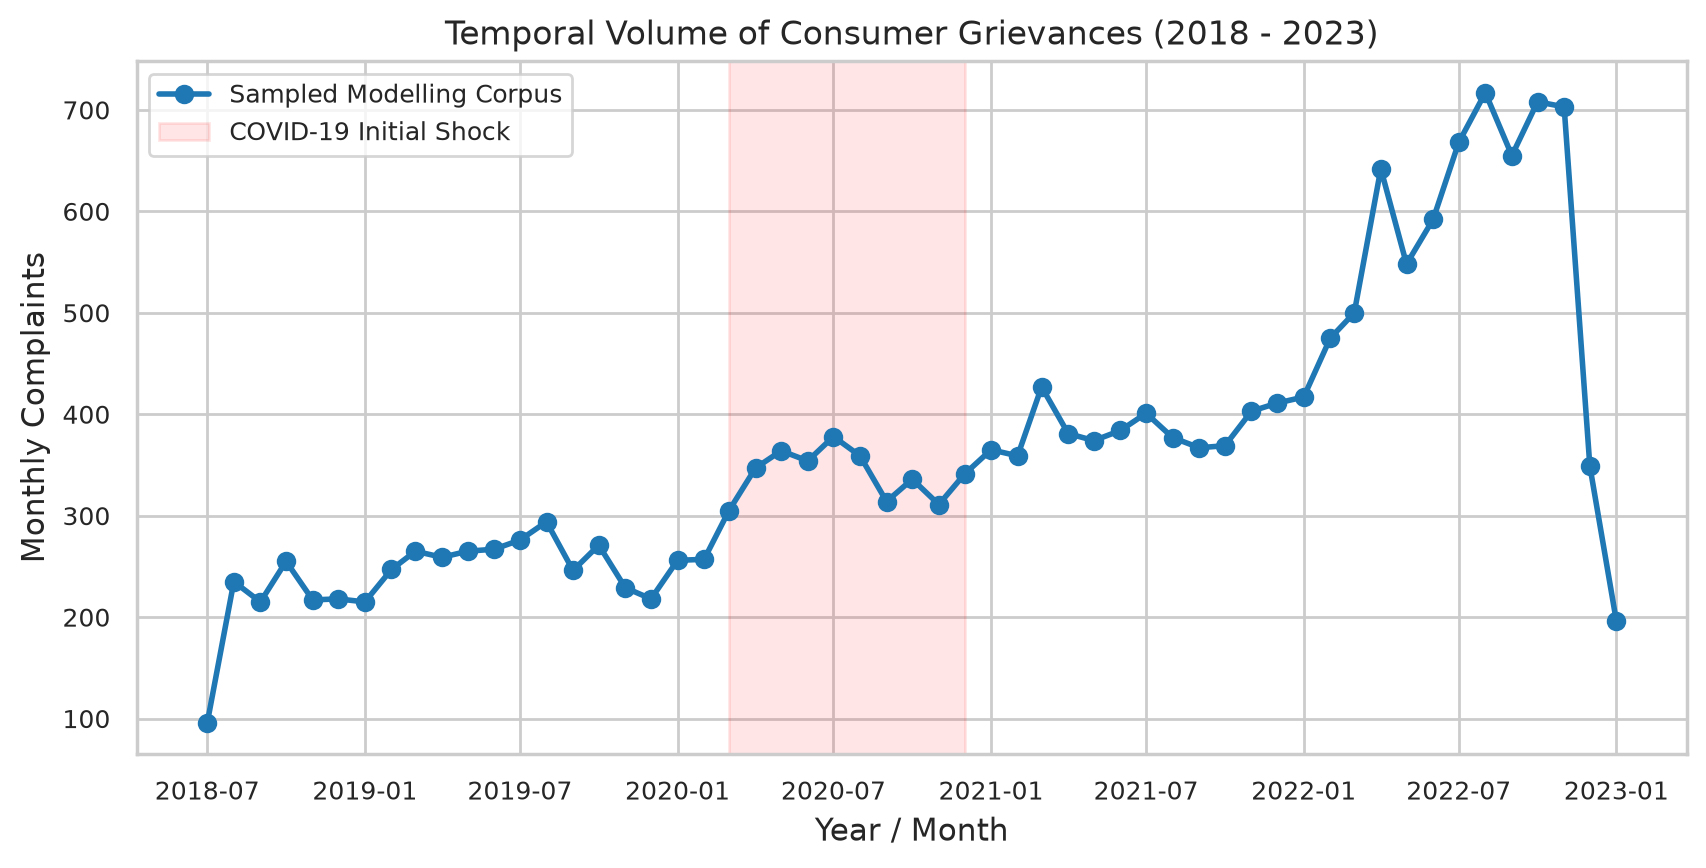

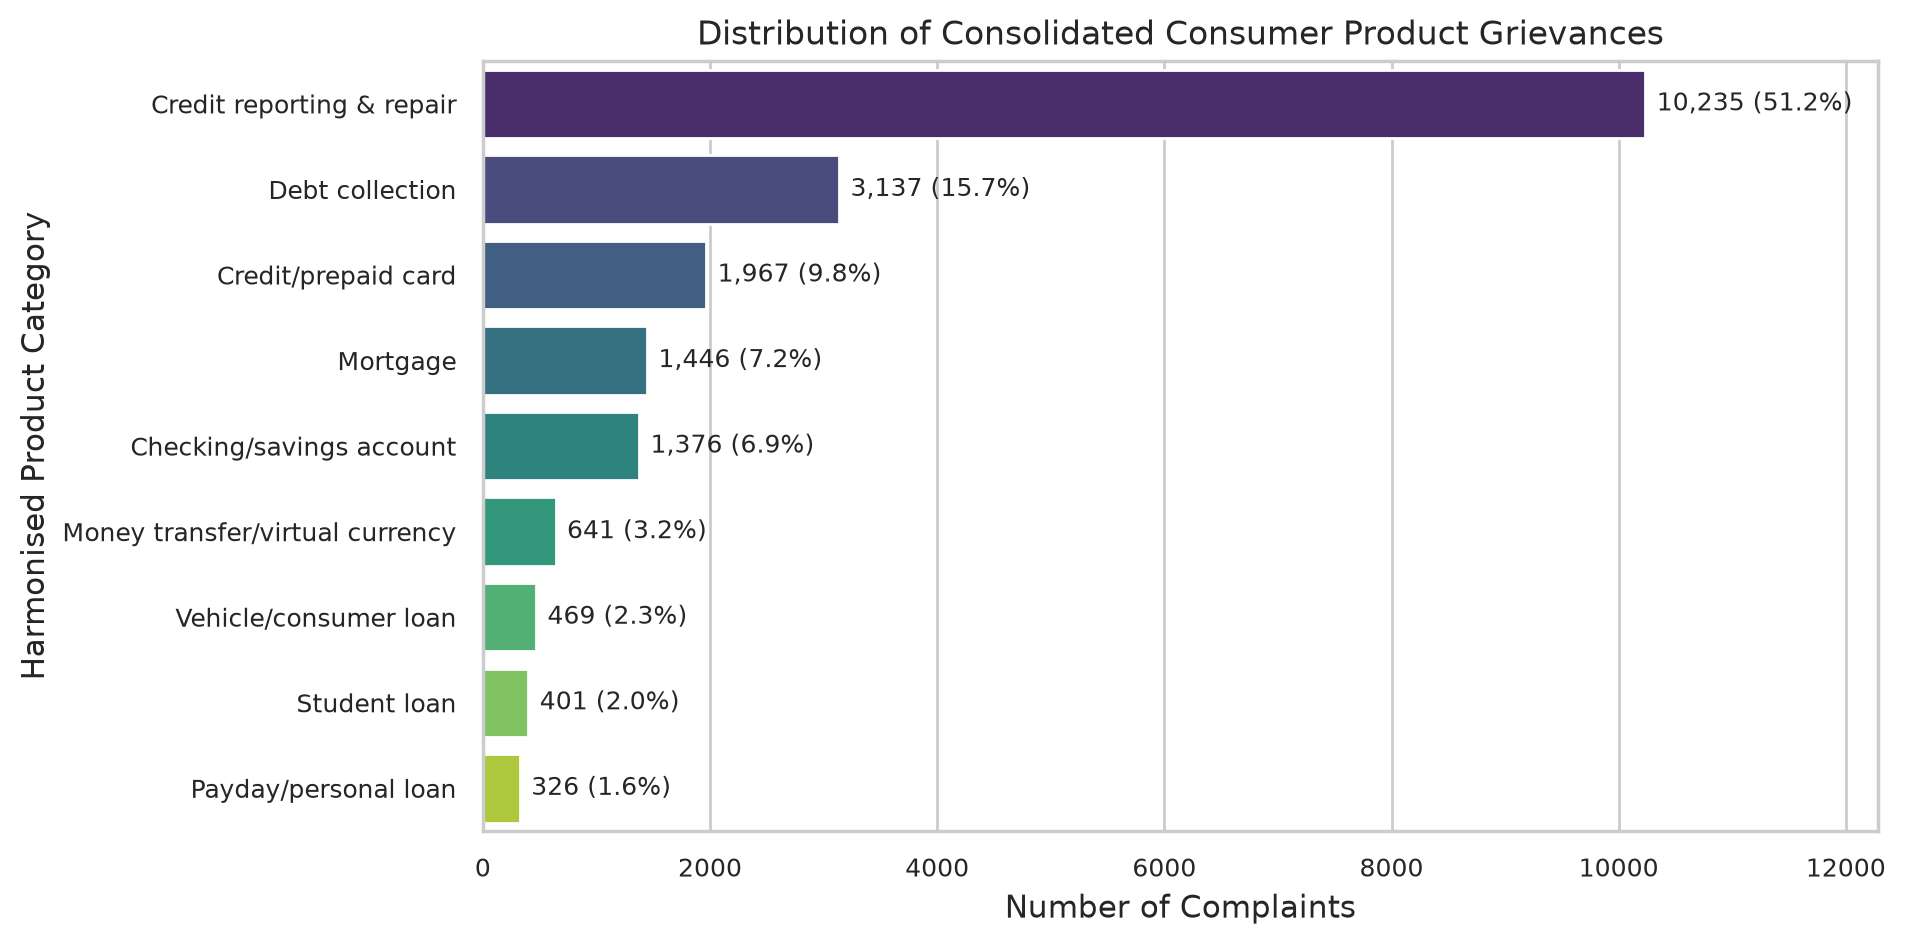

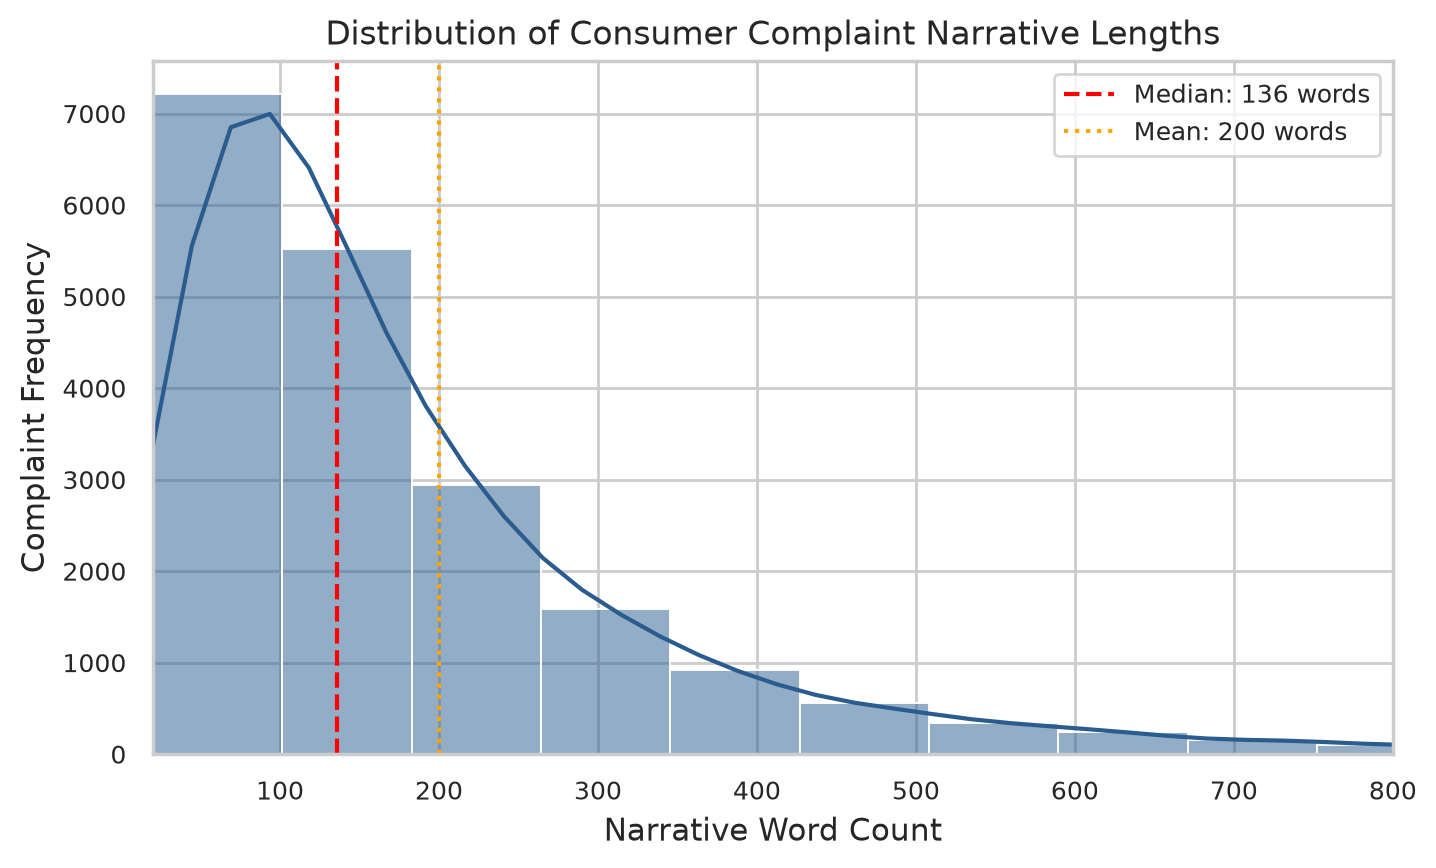

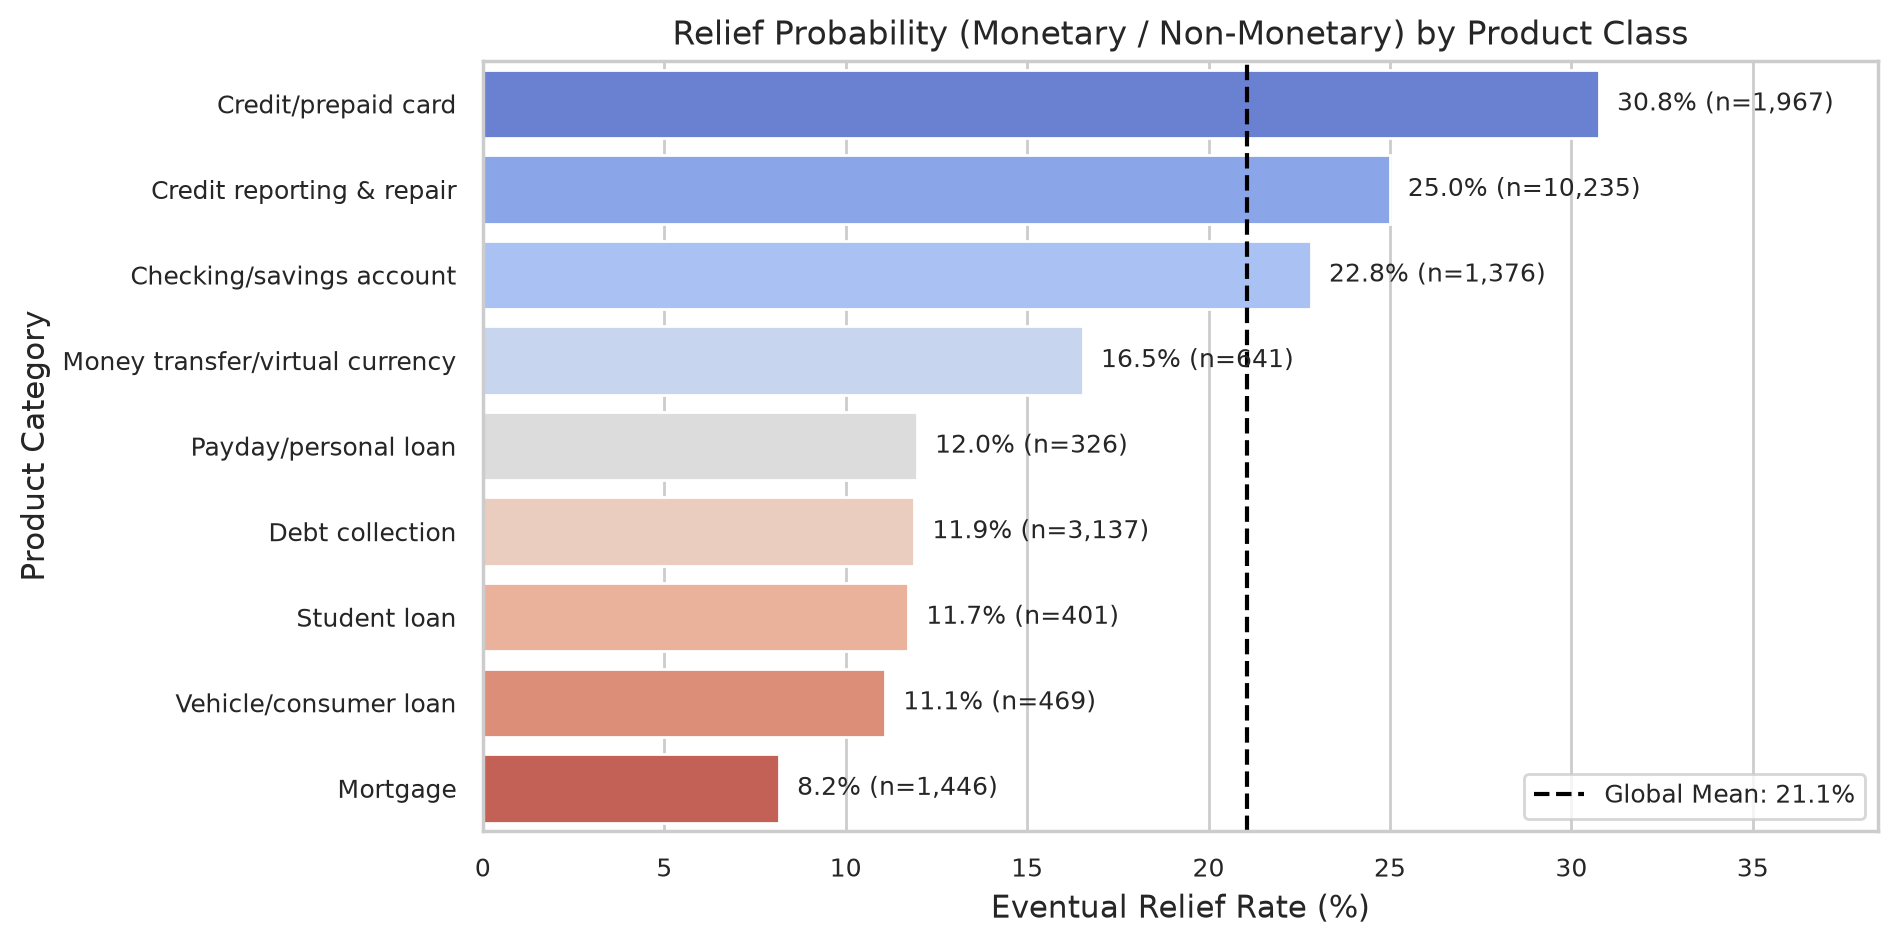

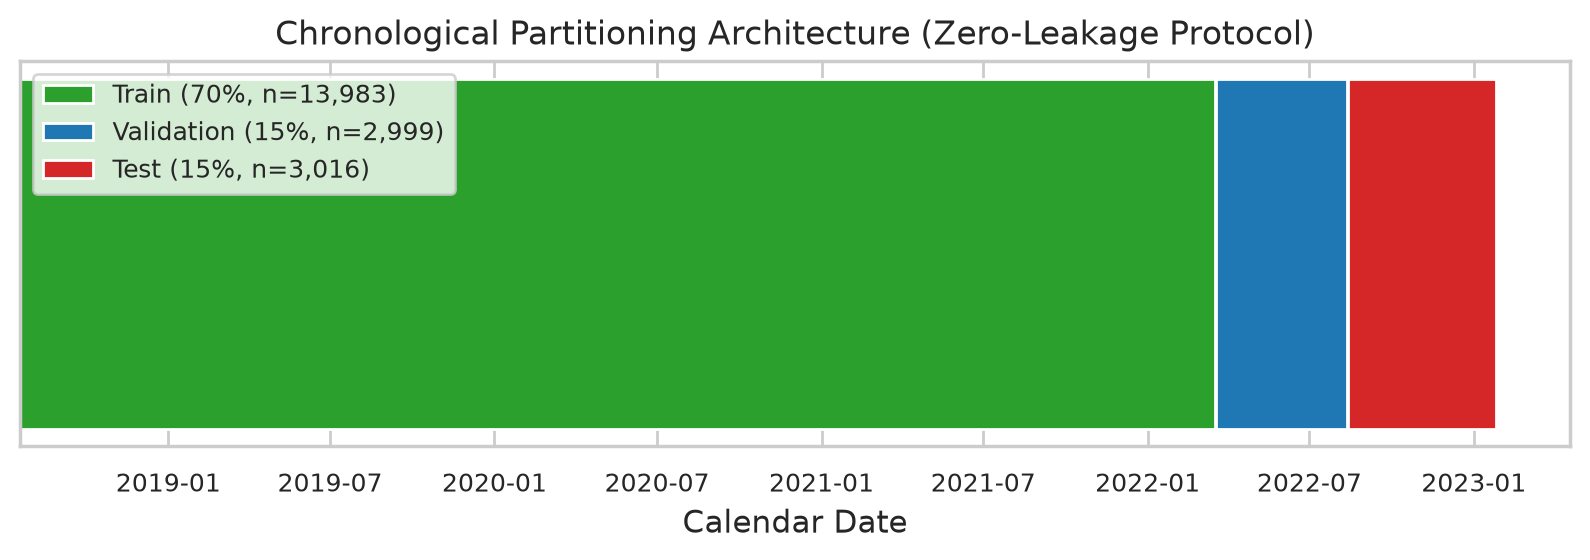

In [3]:
from IPython.display import Image, display

# Display generated publication figures from results/figures
display(Image(filename='../results/figures/fig_01_funnel.png'))
display(Image(filename='../results/figures/fig_02_monthly_volume.png'))
display(Image(filename='../results/figures/fig_03_product_distribution.png'))
display(Image(filename='../results/figures/fig_04_narrative_length.png'))
display(Image(filename='../results/figures/fig_05_relief_rate_by_product.png'))
display(Image(filename='../results/figures/fig_06_split_timeline.png'))


### 3. Key Data Quality Findings & Methodological Implications

1. **Severe Imbalance in Financial Product Classes:**
   - *Observation:* Credit reporting & repair and Debt collection constitute over 60% of complaints.
   - *Implication for Methodology:* Standard accuracy is an invalid headline metric. Class-weighted loss functions and Macro-F1 are mandatory.

2. **Skewed Complaint Length & Boilerplate Noise:**
   - *Observation:* Narratives exhibit heavy right-skewed length (median ~90 words, max > 1,000 words).
   - *Implication for Preprocessing:* Sublinear TF scaling ($1 + \log(\text{TF})$) is essential to down-weight repetitive lexical tokens.

3. **Temporal Trend Non-Stationarity & Macro Shocks:**
   - *Observation:* Pronounced spike in complaint density occurred in 2020–2021 post-CARES Act and pandemic stimulus.
   - *Implication for Split Protocol:* Random train/test cross-validation induces severe temporal leakage. Chronological splits (Train: 2018–2022-03, Val: 2022-03–2022-08, Test: 2022-08+) are mandatory.

4. **Product-Conditioned Relief Disparity:**
   - *Observation:* Eventual relief rates vary dramatically across financial domains (Credit cards & Checking ~20% vs Credit reporting <10%).
   - *Implication for Relief Modeling:* Single global classification thresholds will fail. Calibrated probabilistic predictions and top-$k$ triage ranking are required.
